# 07b – EV Structural Readiness Index (EVISION 360)

**අරමුණ:** රටක **ව්‍යුහාත්මක** EV readiness (ආර්ථික ධාරිතාව, නාගරීකරණය, charging infrastructure) මැනීමට විනිවිද පෙනෙන composite index එකක්, ඒක **කොච්චර විශ්වාස කරන්න පුළුවන්ද** කියලා පෙන්වීමත් එක්ක.

> **මෙය අප විසින් නිර්මාණය කරන analytical index එකක්. Official global ranking එකක් නෙවෙයි.**

**Blueprint එකෙන් වෙනස:** මුල් සූත්‍රයේ `EVRI = w₁S + w₂C + w₃E + w₄U` හි **S (EV adoption score) අයින් කළා.** Adoption index එකට දැම්මොත් "readiness adoption එක්ක align වෙනවා" කියලා validate කරන එක circular වෙනවා (අන්තිමට adoption තමයි මැනෙන්නේ).

| Index | Components | Universe |
| --- | --- | --- |
| **Core** (ප්‍රධාන) | E: GDP per capita (log) · U: urban population % | World Bank economies 200ක් (**Sri Lanka ඇතුළුව**) |
| **Extended** | E + U + C: public chargers per 100k people | Charging data ඇති රටවල් (~43) |

**ක්‍රමය:** හැම component එකක්ම **percentile rank** (0–100) බවට හරවලා, **සමාන weights** වලින් සාමාන්‍යය ගන්නවා. Weights data වලින් "ඉගෙනගත්තේ" නැහැ: Phase 05–06 වලදී ආර්ථික සාධක adoption දුර්වලව පැහැදිලි කරන බව පෙන්වපු නිසා regression-based weights සාධාරණීකරණය කරන්න බැහැ. ඒ වෙනුවට **sensitivity analysis** එකෙන් weights වෙනස් වුණොත් ranking කොච්චර වෙනස් වෙනවාද පෙන්වනවා.

| Section | කරන දේ |
| --- | --- |
| 1 | Index නිර්මාණය |
| 2 | Validation: adoption එක්ක කොච්චර align වෙනවාද? |
| 3 | Extended index (charging) සහ එහි සීමාව |
| 4 | Sensitivity: weights, normalization, components, random weights |
| 5 | Opportunity countries (ready, ඒත් adoption අඩු) |
| 6 | Sri Lanka lens |
| 7 | Findings සහ සීමාවන් |

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.decomposition import PCA
from sqlalchemy import text

warnings.filterwarnings("ignore")
ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src/ingestion"))
from db import get_engine

engine = get_engine()
FIG = ROOT / "reports/figures"; FIG.mkdir(parents=True, exist_ok=True)
OUT = ROOT / "data/processed"; OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RNG = np.random.default_rng(42)

BG, PANEL, TXT, GRID = "#0b1426", "#0f1d36", "#e6f1ff", "#22345a"
CYAN, GREEN, AMBER, PINK, GREY = "#00e5ff", "#39ff88", "#ffb347", "#ff5ea8", "#8fa3c7"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": PANEL, "savefig.facecolor": BG, "text.color": TXT,
    "axes.labelcolor": TXT, "axes.edgecolor": GRID, "xtick.color": TXT, "ytick.color": TXT,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.alpha": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "legend.facecolor": PANEL, "legend.edgecolor": GRID,
})


def q(sql, params=None):
    with engine.connect() as conn:
        conn.exec_driver_sql("SET search_path TO evision")
        return pd.read_sql(text(sql), conn, params=params)


def save(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight"); print("saved", name)


def spearman_ci(a, b, n=2000):
    """Spearman rho with a bootstrap 95% CI (countries resampled)."""
    a, b = np.asarray(a), np.asarray(b)
    rho = stats.spearmanr(a, b)[0]
    boots = []
    for _ in range(n):
        i = RNG.integers(0, len(a), len(a))
        boots.append(stats.spearmanr(a[i], b[i])[0])
    return rho, *np.nanpercentile(boots, [2.5, 97.5])


YEAR = 2024
econ = q("""SELECT g.geo_code, g.geo_name, e.gdp_per_capita_usd, e.urban_pop_pct, e.population, e.inflation_pct
            FROM fact_economic_indicators e JOIN dim_geography g USING (geo_key)
            WHERE g.geo_type = 'country' AND e.year = :y""", {"y": YEAR})
share = q("""SELECT g.geo_code, f.value AS ev_share FROM fact_ev_market_annual f JOIN dim_geography g USING (geo_key)
             JOIN dim_indicator i USING (indicator_key) JOIN dim_scenario s USING (scenario_key)
             WHERE i.parameter_code = 'ev_sales_share' AND i.vehicle_mode = 'Cars' AND i.powertrain = 'EV'
               AND s.scenario_code = 'Historical' AND g.geo_type = 'country' AND f.year = :y AND NOT f.is_suspect_value""", {"y": YEAR})
chargers = q("""SELECT g.geo_code, SUM(f.value) AS charging_points FROM fact_charging_infrastructure f JOIN dim_geography g USING (geo_key)
                JOIN dim_indicator i USING (indicator_key) JOIN dim_scenario s USING (scenario_key)
                WHERE i.parameter_code = 'charging_points' AND s.scenario_code = 'Historical' AND g.geo_type = 'country'
                  AND f.year = :y GROUP BY 1""", {"y": YEAR})
d = econ.merge(share, on="geo_code", how="left").merge(chargers, on="geo_code", how="left")
d["chargers_per_100k"] = d["charging_points"] / d["population"] * 1e5
d["log_gdp"] = np.log10(d["gdp_per_capita_usd"])
print(f"{YEAR}: {len(d)} economies | GDP and urban both available: {int(d[['gdp_per_capita_usd', 'urban_pop_pct']].notna().all(axis=1).sum())} "
      f"| EV share available: {int(d['ev_share'].notna().sum())} | charging data: {int(d['chargers_per_100k'].notna().sum())}")

2024: 217 economies | GDP and urban both available: 200 | EV share available: 60 | charging data: 43


## 1. Index නිර්මාණය

In [2]:
pct = lambda s: s.rank(pct=True) * 100            # percentile rank 0-100 (ties share the average rank)

core = d.dropna(subset=["gdp_per_capita_usd", "urban_pop_pct"]).reset_index(drop=True)
core["E"], core["U"] = pct(core["log_gdp"]), pct(core["urban_pop_pct"])
core["core_index"] = 0.5 * core["E"] + 0.5 * core["U"]
core["core_rank"] = core["core_index"].rank(ascending=False, method="min").astype(int)
core["core_percentile"] = pct(core["core_index"])
print(f"Core index universe: {len(core)} economies. Correlation between E and U (Spearman): {stats.spearmanr(core['E'], core['U'])[0]:.2f}")
cols = ["geo_name", "gdp_per_capita_usd", "urban_pop_pct", "E", "U", "core_index", "core_rank"]
print(chr(10) + "Highest readiness:"); print(core.nsmallest(5, "core_rank")[cols].round(1).to_string(index=False))
print(chr(10) + "Lowest readiness:"); print(core.nlargest(5, "core_rank")[cols].round(1).to_string(index=False))
print(chr(10) + "Sri Lanka:"); print(core[core["geo_code"] == "LKA"][cols].round(1).to_string(index=False))

Core index universe: 200 economies. Correlation between E and U (Spearman): 0.65

Highest readiness:
      geo_name  gdp_per_capita_usd  urban_pop_pct     E    U  core_index  core_rank
        Monaco            288001.6          100.0 100.0 97.8        98.9          1
       Bermuda            142250.4          100.0  99.0 97.8        98.4          2
Cayman Islands            104292.9          100.0  97.0 97.8        97.4          3
     Singapore             94896.6          100.0  96.5 97.8        97.1          4
    Luxembourg            137781.7           94.8  98.5 93.0        95.8          5

Lowest readiness:
   geo_name  gdp_per_capita_usd  urban_pop_pct   E   U  core_index  core_rank
     Malawi               522.4           17.3 2.0 1.5         1.8        200
    Burundi               216.2           24.8 0.5 6.0         3.2        199
      Niger               729.9           18.0 4.5 2.5         3.5        198
Afghanistan               416.9           25.7 1.0 6.5         3

## 2. Validation: adoption එක්ක කොච්චර align වෙනවාද?

Index එක **EV adoption (2024 EV share)** එක්ක Spearman correlation එකෙන් සසඳනවා (bootstrap 95% CI). **වැදගත් සසඳීම:** composite index එක GDP පමණක් (සරලම component එක) ට වඩා හොඳ නම් පමණයි composite එකෙන් වටිනාකමක් තියෙන්නේ.

Alignment with EV share 2024 (n = 60 countries):
             measure  n  rho  ci_low  ci_high
GDP per capita alone 60 0.52    0.25     0.74
       Urban % alone 60 0.35    0.09     0.58
  Core index (E + U) 60 0.48    0.22     0.68
saved 24_readiness_vs_adoption.png


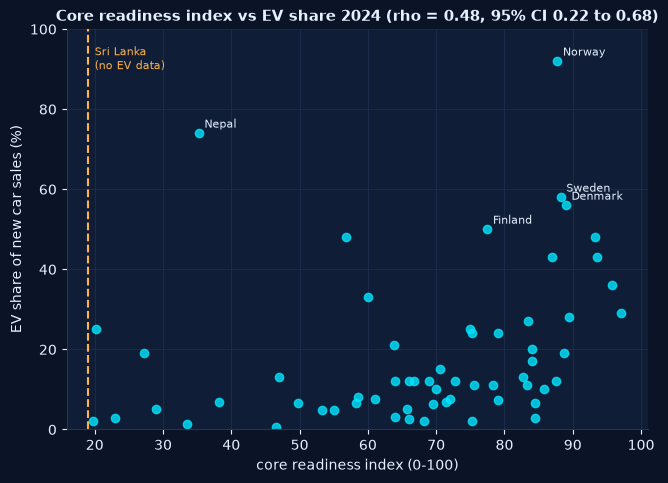

In [3]:
ev = core.dropna(subset=["ev_share"]).reset_index(drop=True)
rows = []
for label, col in [("GDP per capita alone", "log_gdp"), ("Urban % alone", "urban_pop_pct"), ("Core index (E + U)", "core_index")]:
    rho, lo, hi = spearman_ci(ev[col], ev["ev_share"]); rows.append({"measure": label, "n": len(ev), "rho": rho, "ci_low": lo, "ci_high": hi})
val_core = pd.DataFrame(rows)
print(f"Alignment with EV share {YEAR} (n = {len(ev)} countries):"); print(val_core.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.scatter(ev["core_index"], ev["ev_share"], color=CYAN, alpha=0.8)
for _, r in ev.nlargest(5, "ev_share").iterrows():
    ax.annotate(r["geo_name"], (r["core_index"], r["ev_share"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
lka_idx = core.loc[core["geo_code"] == "LKA", "core_index"].iloc[0]
ax.axvline(lka_idx, color=AMBER, ls="--"); ax.text(lka_idx + 1, 90, "Sri Lanka" + chr(10) + "(no EV data)", color=AMBER, fontsize=8)
r0 = val_core.iloc[2]
ax.set(title=f"Core readiness index vs EV share {YEAR} (rho = {r0['rho']:.2f}, 95% CI {r0['ci_low']:.2f} to {r0['ci_high']:.2f})",
       xlabel="core readiness index (0-100)", ylabel="EV share of new car sales (%)", ylim=(0, 100))
save(fig, "24_readiness_vs_adoption.png"); plt.show()

**කියවන විදිහ:** Composite index එකේ ρ, "GDP පමණක්" ට වඩා වැඩි නැත්නම්, GDP සහ urbanization එකතු කිරීමෙන් adoption සමඟ සම්බන්ධය වැඩි වෙලා නැහැ. එහෙම නම් index එක **readiness වල විස්තරාත්මක සාරාංශයක්** විදිහට පමණක් භාවිතා කළ යුතුයි, adoption අනුමාන කරන මිනුමක් විදිහට නෙවෙයි.

## 3. Extended index (charging එක්ක) සහ එහි සීමාව

Public chargers per 100,000 people එකතු කරලා (charging data ඇති රටවල් පමණයි, ඒ නිසා percentile ranks ඒ රටවල් අතරේම ගණනය කරනවා).

**අවවාදය (circularity):** Charging points ඉදි වෙන්නේ EV ඉල්ලුම තියෙන තැන්වල. ඒ නිසා charging component එක adoption එක්ක ඉහළින් align වෙන එක "readiness හොඳ predictor එකක්" කියන එක නෙවෙයි, ඒක ඉල්ලුම සහ සැපයුම අන්‍යෝන්‍ය බලපෑමක්.

Same 43 countries (those with charging data):
                   measure  n  rho  ci_low  ci_high
      GDP per capita alone 43 0.62    0.36     0.79
        Core index (E + U) 43 0.53    0.24     0.74
   Chargers per 100k alone 43 0.77    0.57     0.89
Extended index (E + U + C) 43 0.68    0.44     0.84
saved 25_readiness_alignment.png


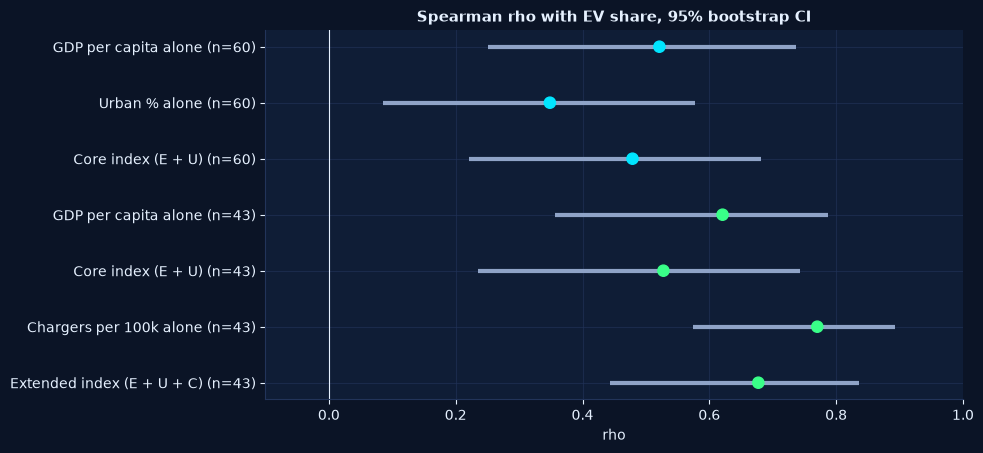

In [4]:
ext = core.dropna(subset=["chargers_per_100k"]).reset_index(drop=True)
ext["E"], ext["U"], ext["C"] = pct(ext["log_gdp"]), pct(ext["urban_pop_pct"]), pct(ext["chargers_per_100k"])
ext["ext_index"] = (ext["E"] + ext["U"] + ext["C"]) / 3
ext["core_index_subset"] = (ext["E"] + ext["U"]) / 2
ee = ext.dropna(subset=["ev_share"])
rows = []
for label, col in [("GDP per capita alone", "log_gdp"), ("Core index (E + U)", "core_index_subset"),
                   ("Chargers per 100k alone", "chargers_per_100k"), ("Extended index (E + U + C)", "ext_index")]:
    rho, lo, hi = spearman_ci(ee[col], ee["ev_share"]); rows.append({"measure": label, "n": len(ee), "rho": rho, "ci_low": lo, "ci_high": hi})
val_ext = pd.DataFrame(rows)
print(f"Same {len(ee)} countries (those with charging data):"); print(val_ext.round(2).to_string(index=False))

allv = pd.concat([val_core.assign(group=f"all {len(ev)} countries"), val_ext.assign(group=f"{len(ee)} with charging data")], ignore_index=True)
fig, ax = plt.subplots(figsize=(9, 4.8))
yy = np.arange(len(allv))[::-1]
ax.hlines(yy, allv["ci_low"], allv["ci_high"], color=GREY, lw=3)
ax.scatter(allv["rho"], yy, color=[CYAN] * len(val_core) + [GREEN] * len(val_ext), s=65, zorder=3)
ax.set_yticks(yy); ax.set_yticklabels([f"{m} (n={n})" for m, n in zip(allv["measure"], allv["n"])])
ax.axvline(0, color=TXT, lw=0.8); ax.set_xlim(-0.1, 1)
ax.set(title="Spearman rho with EV share, 95% bootstrap CI", xlabel="rho")
save(fig, "25_readiness_alignment.png"); plt.show()

## 4. Sensitivity analysis

Index එකේ ranking **weights, normalization සහ component තේරීම** වලට කොච්චර සංවේදීද?

**(a) Weight schemes** (core index): සමාන (50/50), PCA (1වන principal component loadings), E-heavy (70/30), U-heavy (30/70). Baseline ranking එක්ක Spearman correlation සහ Sri Lanka ගේ rank.
**(b) Normalization:** percentile rank vs winsorized min-max (5–95 percentile).
**(c) Component set:** E පමණක්, U පමණක්, core, core + stability (inflation අඩු වීම).
**(d) Random weights:** Dirichlet draws 2,000ක්, හැම රටකම rank එකේ 5–95% පරාසය. *Any weights* (α = 1: simplex එකේ ඕනෑම weights) සහ *near-equal* (α = 10).

In [5]:
def rank_desc(values):
    return pd.Series(values).rank(ascending=False, method="min").astype(int).values


lka = core.index[core["geo_code"] == "LKA"][0]
base_rank = core["core_rank"].values
Z = core[["E", "U"]]
pca = PCA(1).fit((Z - Z.mean()) / Z.std()); w_pca = np.abs(pca.components_[0]); w_pca = w_pca / w_pca.sum()

def winsorized_minmax(s):
    """Clip to the 5th-95th percentile, then rescale to 0-100."""
    c = s.clip(s.quantile(0.05), s.quantile(0.95))
    return (c - c.min()) / (c.max() - c.min()) * 100


E_w, U_w = winsorized_minmax(core["log_gdp"]), winsorized_minmax(core["urban_pop_pct"])

schemes = {
    "Equal 50/50 (baseline)": 0.5 * core["E"] + 0.5 * core["U"],
    f"PCA weights {w_pca[0]:.2f}/{w_pca[1]:.2f}": w_pca[0] * core["E"] + w_pca[1] * core["U"],
    "E-heavy 70/30": 0.7 * core["E"] + 0.3 * core["U"],
    "U-heavy 30/70": 0.3 * core["E"] + 0.7 * core["U"],
    "Winsorized min-max, equal": 0.5 * E_w + 0.5 * U_w,
    "E only (GDP)": core["E"],
    "U only (urban %)": core["U"],
}
stab = core.dropna(subset=["inflation_pct"]).copy()
stab["S"] = pct(-stab["inflation_pct"])
rows = []
for name, idx in schemes.items():
    r = rank_desc(idx)
    rows.append({"variant": name, "spearman_vs_baseline_ranking": stats.spearmanr(r, base_rank)[0], "sri_lanka_rank": int(r[lka]), "of": len(core)})
sens = pd.DataFrame(rows)
print(sens.round(2).to_string(index=False))

# core + stability on the economies where inflation is available
stab["idx3"] = (stab["E"] + stab["U"] + stab["S"]) / 3
st_ev = stab.dropna(subset=["ev_share"])
rho_s3 = stats.spearmanr(st_ev["idx3"], st_ev["ev_share"])[0]
rho_s2 = stats.spearmanr((st_ev["E"] + st_ev["U"]) / 2, st_ev["ev_share"])[0]
print(f"{chr(10)}Adding a stability component (low inflation), n = {len(st_ev)} EV countries: rho with EV share {rho_s3:.2f} vs {rho_s2:.2f} for core on the same countries")

                  variant  spearman_vs_baseline_ranking  sri_lanka_rank  of
   Equal 50/50 (baseline)                          1.00             165 200
    PCA weights 0.50/0.50                          1.00             165 200
            E-heavy 70/30                          0.98             153 200
            U-heavy 30/70                          0.98             184 200
Winsorized min-max, equal                          1.00             166 200
             E only (GDP)                          0.90             131 200
         U only (urban %)                          0.91             195 200

Adding a stability component (low inflation), n = 60 EV countries: rho with EV share 0.50 vs 0.48 for core on the same countries


Rank interval width under ANY weights (5-95%): median 28 places out of 200 | under NEAR-EQUAL weights: median 11

Sri Lanka: baseline rank 165, 5-95% range 135-195 (any weights), 153-183 (near-equal)
saved 26_readiness_rank_stability.png


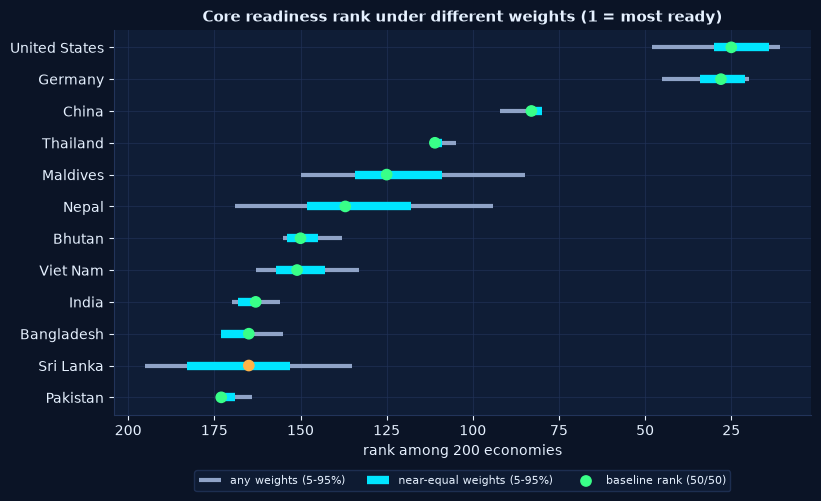

In [6]:
def random_weight_ranks(alpha, draws=2000):
    ranks = np.empty((draws, len(core)), dtype=int)
    for k in range(draws):
        w = RNG.dirichlet([alpha, alpha])
        ranks[k] = rank_desc(w[0] * core["E"].values + w[1] * core["U"].values)
    return ranks


rk_any, rk_near = random_weight_ranks(1.0), random_weight_ranks(10.0)
core["rank_p05_any"], core["rank_p95_any"] = np.percentile(rk_any, 5, axis=0), np.percentile(rk_any, 95, axis=0)
core["rank_p05_near"], core["rank_p95_near"] = np.percentile(rk_near, 5, axis=0), np.percentile(rk_near, 95, axis=0)
core["interval_width_any"] = core["rank_p95_any"] - core["rank_p05_any"]
print(f"Rank interval width under ANY weights (5-95%): median {core['interval_width_any'].median():.0f} places out of {len(core)} "
      f"| under NEAR-EQUAL weights: median {(core['rank_p95_near'] - core['rank_p05_near']).median():.0f}")
print(chr(10) + f"Sri Lanka: baseline rank {int(base_rank[lka])}, 5-95% range {core.loc[lka, 'rank_p05_any']:.0f}-{core.loc[lka, 'rank_p95_any']:.0f} (any weights), "
      f"{core.loc[lka, 'rank_p05_near']:.0f}-{core.loc[lka, 'rank_p95_near']:.0f} (near-equal)")

focus = [c for c in ["LKA", "IND", "BGD", "PAK", "NPL", "MDV", "BTN", "VNM", "THA", "CHN", "DEU", "USA"] if c in set(core["geo_code"])]
f = core[core["geo_code"].isin(focus)].sort_values("core_rank").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 5))
yy = np.arange(len(f))[::-1]
ax.hlines(yy, f["rank_p05_any"], f["rank_p95_any"], color=GREY, lw=3, label="any weights (5-95%)")
ax.hlines(yy, f["rank_p05_near"], f["rank_p95_near"], color=CYAN, lw=6, label="near-equal weights (5-95%)")
ax.scatter(f["core_rank"], yy, color=[AMBER if g == "LKA" else GREEN for g in f["geo_code"]], zorder=3, s=55, label="baseline rank (50/50)")
ax.set_yticks(yy); ax.set_yticklabels(f["geo_name"]); ax.invert_xaxis()
ax.set(title="Core readiness rank under different weights (1 = most ready)", xlabel=f"rank among {len(core)} economies"); ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3)
save(fig, "26_readiness_rank_stability.png"); plt.show()

**කියවන විදිහ:** Rank interval පළල් නම් (රටක rank එක weights අනුව ගොඩක් වෙනස් වෙනවා), එක rank number එකක් "ස්ථාවර" කියලා ඉදිරිපත් කරන්න බැහැ. **Percentile band** එකක් (උදා: "පහළ තුනෙන් එක") වඩා අවංකයි. Components දෙකක් පමණක් ඇති core index එකේ ranking, weights වලට සාමාන්‍යයෙන් සංවේදීයි.

## 5. Opportunity countries

"Readiness ඉහළයි, ඒත් adoption අඩුයි" රටවල්: **gap = readiness percentile − adoption percentile** (EV data ඇති රටවල් අතර). ඉහළ ධනාත්මක gap = බලාපොරොත්තු වුණාට වඩා අඩු adoption. **Robustness:** random weights 2,000ක් යටතේ රටක් top-10 gap එකේ ඇතුළත් වන සංඛ්‍යාතය.

**මෙය හේතු කියන්නේ නැහැ.** Policy, ආනයන බදු, ඉන්ධන මිල, vehicle සැපයුම, hybrid වලට මනාපය (උදා: Japan) වැනි සාධක index එකේ නැහැ. ඒ නිසා මේ ලැයිස්තුව "වැඩිදුර පරීක්ෂා කළ යුතු රටවල්" පමණයි.

Readiness above adoption (opportunity candidates):
            geo_name  core_index  ev_share   gap  freq_top10_gap
               Japan       84.50       2.8 67.50            1.00
               Chile       75.25       2.1 53.33            1.00
United Arab Emirates       84.50       6.5 53.33            1.00
       United States       85.75      10.0 40.83            0.72
              Mexico       68.25       2.2 35.00            0.86
         South Korea       79.00       7.4 34.17            0.91
           Australia       87.50      12.0 32.50            0.84
              Russia       66.00       2.5 29.17            0.67

Adoption above readiness (over-performers):
geo_name  core_index  ev_share    gap  freq_bottom10_gap
   Nepal       35.25      74.0 -86.67                1.0
 Lao PDR       20.25      25.0 -72.50                1.0
   China       56.75      48.0 -67.50                1.0
Viet Nam       27.25      19.0 -59.17                1.0
Portugal       60.00      33.0 -55

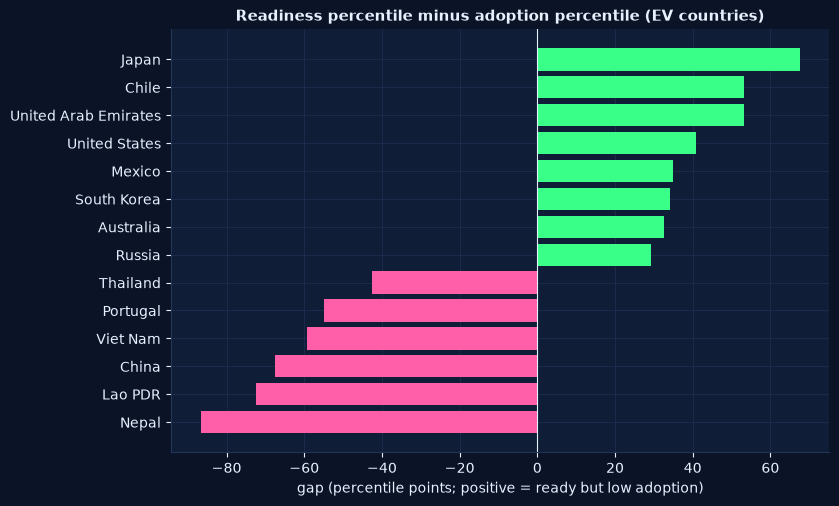

In [7]:
ev = core.dropna(subset=["ev_share"]).reset_index(drop=True)
adopt_pct = pct(ev["ev_share"]).values
ev_pos = [core.index[core["geo_code"] == g][0] for g in ev["geo_code"]]
Ev, Uv = core["E"].values[ev_pos], core["U"].values[ev_pos]

gap_base = pct(pd.Series(0.5 * Ev + 0.5 * Uv)).values - adopt_pct
ev["gap"] = gap_base
top_counts, bottom_counts = np.zeros(len(ev)), np.zeros(len(ev))
for _ in range(2000):
    w = RNG.dirichlet([1, 1])
    gap = pct(pd.Series(w[0] * Ev + w[1] * Uv)).values - adopt_pct
    top_counts[np.argsort(-gap)[:10]] += 1
    bottom_counts[np.argsort(gap)[:10]] += 1
ev["freq_top10_gap"], ev["freq_bottom10_gap"] = top_counts / 2000, bottom_counts / 2000
ev["readiness_pct_ev"] = pct(0.5 * ev["E"] + 0.5 * ev["U"])
cols = ["geo_name", "core_index", "ev_share", "gap", "freq_top10_gap"]
opp = ev.nlargest(8, "gap"); over = ev.nsmallest(6, "gap")
print("Readiness above adoption (opportunity candidates):"); print(opp[cols].round(2).to_string(index=False))
print(chr(10) + "Adoption above readiness (over-performers):"); print(over[["geo_name", "core_index", "ev_share", "gap", "freq_bottom10_gap"]].round(2).to_string(index=False))
robust_opp = ev[ev["freq_top10_gap"] >= 0.8]["geo_name"].tolist()
print(chr(10) + "Robust opportunity candidates (in the top-10 gap in >= 80% of random-weight draws):", robust_opp)

pl = pd.concat([opp, over]).drop_duplicates("geo_code").sort_values("gap")
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.barh(pl["geo_name"], pl["gap"], color=[GREEN if g > 0 else PINK for g in pl["gap"]])
ax.axvline(0, color=TXT, lw=0.8)
ax.set(title="Readiness percentile minus adoption percentile (EV countries)", xlabel="gap (percentile points; positive = ready but low adoption)")
save(fig, "27_opportunity_gap.png"); plt.show()

## 6. Sri Lanka lens

In [8]:
sl = core.loc[lka]
lo_a, hi_a = sl["rank_p05_any"], sl["rank_p95_any"]
print(f"Sri Lanka core readiness index: {sl['core_index']:.1f} (percentile {sl['core_percentile']:.0f}), rank {int(sl['core_rank'])} of {len(core)}")
print(f"  GDP component (E): percentile {sl['E']:.0f}, rank {int(rank_desc(core['E'])[lka])} of {len(core)}")
print(f"  Urban component (U): percentile {sl['U']:.0f}, rank {int(rank_desc(core['U'])[lka])} of {len(core)}")
print(f"  Rank under any weights: {lo_a:.0f}-{hi_a:.0f}; under near-equal weights: {sl['rank_p05_near']:.0f}-{sl['rank_p95_near']:.0f}")
print("  Extended index (needs charging data): not available for Sri Lanka")

peers = core[(core["core_index"].between(sl["core_index"] - 10, sl["core_index"] + 10)) & core["ev_share"].notna()]
peers = peers[["geo_name", "core_index", "gdp_per_capita_usd", "urban_pop_pct", "ev_share"]].sort_values("ev_share", ascending=False)
print(chr(10) + f"Countries with EV data and a core index within +/-10 points of Sri Lanka ({len(peers)}):"); print(peers.round(1).to_string(index=False))

Sri Lanka core readiness index: 19.0 (percentile 18), rank 165 of 200
  GDP component (E): percentile 35, rank 131 of 200
  Urban component (U): percentile 3, rank 195 of 200
  Rank under any weights: 135-195; under near-equal weights: 153-183
  Extended index (needs charging data): not available for Sri Lanka

Countries with EV data and a core index within +/-10 points of Sri Lanka (5):
  geo_name  core_index  gdp_per_capita_usd  urban_pop_pct  ev_share
   Lao PDR        20.2              2124.0           39.6      25.0
  Viet Nam        27.2              4716.7           38.5      19.0
Uzbekistan        29.0              3337.5           51.0       5.0
  Cambodia        23.0              2627.9           40.9       2.9
     India        19.8              2592.0           35.4       2.1


**Sri Lanka ගේ urban component එක ගැන සැලකිල්ල:** Sri Lanka ගේ urban population share (World Bank) ඉතා පහළයි. රටවල් අතර "urban" නිර්වචනය වෙනස් වන නිසා (නිල නිර්වචන සමානව නැහැ), මේ component එකේ ranking එක වෙනත් රටවල් එක්ක කෙලින්ම සසඳන්න පරිස්සම් වෙන්න. ඒ නිසා **E-only** (GDP) rank එකත් එක්ක (ඉහළ table එකේ) බලන්න, ඒ දෙක අතර වෙනස පෙන්නන්නේ urban component එකේ බලපෑමයි.

Peers table එක **benchmark එකක්** පමණයි. Sri Lanka ගේ adoption ගැන අනුමානයක් නෙවෙයි: ආනයන ප්‍රතිපත්ති, ඉන්ධන මිල, charging network වැනි Sri Lanka-specific සාධක index එකේ නැහැ.

In [9]:
out = core[["geo_code", "geo_name", "gdp_per_capita_usd", "urban_pop_pct", "E", "U", "core_index", "core_percentile", "core_rank",
            "rank_p05_any", "rank_p95_any", "rank_p05_near", "rank_p95_near", "ev_share"]].copy()
out = out.merge(ext[["geo_code", "chargers_per_100k", "C", "ext_index"]], on="geo_code", how="left")
out = out.merge(ev[["geo_code", "gap", "freq_top10_gap"]], on="geo_code", how="left")
out.insert(0, "year", YEAR)
out.round(3).to_csv(OUT / "ev_readiness_index_2024.csv", index=False)
print(f"saved data/processed/ev_readiness_index_2024.csv ({len(out)} economies)")

saved data/processed/ev_readiness_index_2024.csv (200 economies)


## 7. Findings (data වලින්ම ගණනය කරපු)

In [10]:
c_g, c_i = val_core.set_index("measure").loc["GDP per capita alone"], val_core.set_index("measure").loc["Core index (E + U)"]
e = val_ext.set_index("measure")
worst_alt = sens.loc[sens["variant"].isin(["PCA weights" + f" {w_pca[0]:.2f}/{w_pca[1]:.2f}", "E-heavy 70/30", "U-heavy 30/70", "Winsorized min-max, equal"]), "spearman_vs_baseline_ranking"].min()
print(f"1. Core index = mean of GDP-per-capita and urban-share percentile ranks over {len(core)} economies (Sri Lanka included). Extended index adds public chargers per 100k people for {len(ext)} countries.")
print(f"2. Alignment with EV share {YEAR}: core index rho {c_i['rho']:.2f} (95% CI {c_i['ci_low']:.2f} to {c_i['ci_high']:.2f}) vs GDP alone {c_g['rho']:.2f} "
      f"({c_g['ci_low']:.2f} to {c_g['ci_high']:.2f}) -> the composite is " + ("not better aligned than GDP alone (the gap is small relative to the CIs)." if c_i["rho"] <= c_g["rho"] else "somewhat better aligned than GDP alone."))
print(f"3. Extended index rho {e.loc['Extended index (E + U + C)', 'rho']:.2f} but chargers alone {e.loc['Chargers per 100k alone', 'rho']:.2f} on the same {len(ee)} countries; "
      "charging follows demand, so this is not evidence of predictive power.")
print(f"4. Rankings are fairly stable across reasonable weight and normalization choices (lowest Spearman vs baseline ranking: {worst_alt:.2f}), "
      f"but under arbitrary weights the median country's rank still moves over a {core['interval_width_any'].median():.0f}-place range.")
print(f"5. Sri Lanka: core index {sl['core_index']:.0f}, rank {int(sl['core_rank'])} of {len(core)} (range {lo_a:.0f}-{hi_a:.0f} under any weights): "
      f"GDP percentile {sl['E']:.0f}, urban-share percentile {sl['U']:.0f}. The urban component drives the low position, and the rank range ({hi_a - lo_a:.0f} places) is wider than for the median country ({core['interval_width_any'].median():.0f}) because the two percentiles diverge.")
print(f"6. Opportunity candidates robust to weights (top-10 gap in >= 80% of draws): {robust_opp if robust_opp else 'none'}.")
print(f"7. Adding a low-inflation stability component changed alignment from {rho_s2:.2f} to {rho_s3:.2f} (n = {len(st_ev)}).")

1. Core index = mean of GDP-per-capita and urban-share percentile ranks over 200 economies (Sri Lanka included). Extended index adds public chargers per 100k people for 43 countries.
2. Alignment with EV share 2024: core index rho 0.48 (95% CI 0.22 to 0.68) vs GDP alone 0.52 (0.25 to 0.74) -> the composite is not better aligned than GDP alone (the gap is small relative to the CIs).
3. Extended index rho 0.68 but chargers alone 0.77 on the same 43 countries; charging follows demand, so this is not evidence of predictive power.
4. Rankings are fairly stable across reasonable weight and normalization choices (lowest Spearman vs baseline ranking: 0.98), but under arbitrary weights the median country's rank still moves over a 28-place range.
5. Sri Lanka: core index 19, rank 165 of 200 (range 135-195 under any weights): GDP percentile 35, urban-share percentile 3. The urban component drives the low position, and the rank range (60 places) is wider than for the median country (28) because th

### සීමාවන් සහ ලේඛනගත කළ යුතු දේවල්

- **Official ranking එකක් නෙවෙයි.** Weights (50/50), normalization (percentile rank) සහ component තේරීම අපේ තීරණ.
- Index එක **ව්‍යුහාත්මක** සාධක පමණක් මනිනවා. Policy, vehicle සැපයුම, ඉන්ධන මිල, ආනයන බදු නැහැ. Adoption එක්ක alignment මධ්‍යස්ථයි (ρ ≈ 0.5), ඒ නිසා EV adoption අනුමාන කරන මිනුමක් ලෙස භාවිතා නොකරන්න.
- **Missing data:** Core index සඳහා GDP සහ urban share දෙකම අවශ්‍යයි (economies 17ක් ඇතුළත් නැහැ). Imputation කළේ නැහැ.
- **Universe එකේ ක්ෂුද්‍ර economies සහ territories** (උදා: Monaco, Bermuda, Cayman Islands) ඇතුළත්. ඒවා ඉහළම තැන් ගන්නවා. ඒවා percentile ranks වලට බලපානවා, ඒත් Sri Lanka වැනි රටවල ranking එකට බලපෑම කුඩායි. අවශ්‍ය නම් ජනගහන සීමාවක් (උදා: මිලියන 1+) යෙදීම sensitivity එකක් ලෙස පරීක්ෂා කළ හැකියි.
- **Percentile rank normalization** magnitude නොසලකයි (ධනවත්ම රට සහ දෙවැනි ධනවත්ම රට අතර විශාල වෙනසක් රැඳෙන්නේ නැහැ).
- Extended index charging data ඇති රටවල් වලට පමණයි (නියෛදර්ශනය නියෝජනීය නැති විය හැකියි), සහ charging component එක adoption එකට අන්‍යෝන්‍ය වශයෙන් බලපායි.
- **Sri Lanka**: EV data නැති නිසා validation කරන්න බැහැ. Urban component එකේ නිර්වචන ගැටලුව පැහැදිලි කළා.